In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error


In [30]:
# Data and features
train=pd.read_csv("MLProject2026/data/case1/train1.csv")
test=pd.read_csv("MLProject2026/data/case1/test1.csv")
for df in (train, test):
    df["n"] = df["speed_rpm"] / 1000
    df["Q"] = df["flow_m3_h"]
    df["P"] = df["power_w"]

In [31]:
def make_features(df):
    features = pd.DataFrame()
    for i in range(4):
        for j in range(4):
            if i == 0 and j == 0:
                continue
            features["n" + str(i) + "Q" + str(j)] = df["n"] ** i * df["Q"] ** j
    return features

X_train, y_train = make_features(train), train["P"]
X_test, y_test = make_features(test), test["P"]

In [32]:
all_cols = list(X_train.columns)
n_cols = len(all_cols)

all_subsets = [[]]
for col in all_cols:
    new_subsets = []
    for subset in all_subsets:
        new_subsets.append(subset + [col])
    all_subsets = all_subsets + new_subsets
all_subsets = all_subsets[1:]

In [ ]:
# Cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=30)

def kfold(X, y, cols, cv):
    errors = []
    for train_idx, val_idx in cv.split(X):
        model = LinearRegression().fit(X.iloc[train_idx][cols], y.iloc[train_idx])
        pred = model.predict(X.iloc[val_idx][cols])
        errors.append(mean_squared_error(y.iloc[val_idx], pred))
    return np.array(errors)


results = []
for subset in all_subsets:
    e = kfold(X_train, y_train, subset, kf)
    results.append({"n_terms": len(subset), "features": tuple(subset),
                    "mse": e.mean(), "se": e.std(ddof=1) / np.sqrt(len(e))})
results = pd.DataFrame(results)


best_rows = []
for t in range(1, n_cols + 1):
    models_with_t_terms = results[results["n_terms"] == t]
    best_rows.append(models_with_t_terms.sort_values("mse").iloc[0])
best = pd.DataFrame(best_rows).reset_index(drop=True)

# 1-SE rule
lowest = best.sort_values("mse").iloc[0]
threshold = lowest["mse"] + lowest["se"]
for i in range(len(best)):
    if best.iloc[i]["mse"] <= threshold:
        chosen = best.iloc[i]
        break

print(best[["n_terms", "mse", "se", "features"]].to_string())
print("Chosen:", chosen["n_terms"], "terms:", chosen["features"])

    n_terms           mse           se                                                                                    features
0         1  32616.137215  4660.071872                                                                                     (n3Q0,)
1         2  11727.667815  1835.963761                                                                                (n2Q2, n3Q1)
2         3    131.640745    15.091516                                                                          (n0Q3, n2Q1, n3Q0)
3         4    109.832991    10.299497                                                                    (n0Q3, n1Q2, n2Q1, n3Q0)
4         5    109.819306    10.274606                                                              (n0Q3, n1Q0, n1Q2, n2Q1, n3Q0)
5         6    109.488133    10.117570                                                        (n0Q3, n1Q0, n1Q2, n2Q0, n2Q1, n3Q0)
6         7    109.632365    10.055517                                             

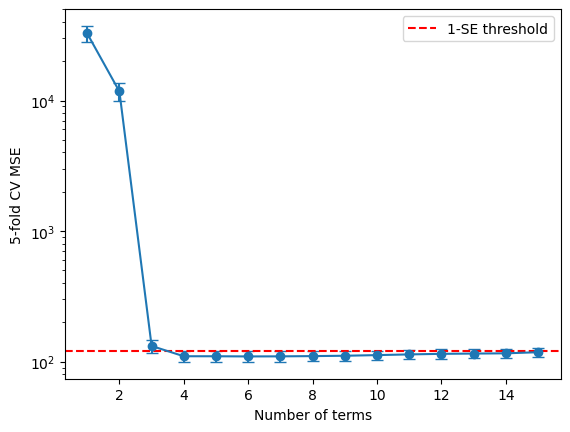

In [34]:
plt.errorbar(best["n_terms"], best["mse"], yerr=best["se"], marker="o", capsize=4)
plt.axhline(threshold, color="red", linestyle="--", label="1-SE threshold")
plt.yscale("log")
plt.xlabel("Number of terms")
plt.ylabel("5-fold CV MSE")
plt.legend()
plt.show()

In [36]:
chosen_cols = list(chosen["features"])

final_model = LinearRegression()
final_model.fit(X_train[chosen_cols], y_train)

y_pred = final_model.predict(X_test[chosen_cols])
residuals = y_test.to_numpy() - y_pred
test_r2   = final_model.score(X_test[chosen_cols], y_test)
print(f"R²:   {test_r2:.4f}")


R²:   0.9996
